In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
from matplotlib.ticker import StrMethodFormatter

from utils import (
    COL_IRIS,
    agreger_dvf_par_iris,
    calculer_zones_tampons,
    cadrer_carte,
    charger_carte_et_transports,
    charger_et_nettoyer_dvf,
    etiqueter_stations,
    rattacher_ventes_aux_iris,
)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "DejaVu Sans", "Arial"]

In [26]:
# Les fichiers sont recherchés relativement au dépôt (ou dans data/ et data/raw/).
CODE_INSEE = "93070"
zone_etude, traces_transport, stations_proches = charger_carte_et_transports(CODE_INSEE)
df_logements = charger_et_nettoyer_dvf(CODE_INSEE)
zone_etude_dvf = agreger_dvf_par_iris(df_logements, zone_etude)


⚠️ 2017 : aucun fichier trouvé
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/dvf-2018.parquet : 2296 lignes pour 2018
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/dvf-2019.parquet : 3140 lignes pour 2019
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/dvf-2020.parquet : 2540 lignes pour 2020
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/93070.2021.csv : 3462 lignes pour 2021
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/93070.2022.csv : 3019 lignes pour 2022
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/93070.2023.csv : 3019 lignes pour 2023
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/93070.2024.csv : 2471 lignes pour 2024
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/93070.2025.csv : 2650 lignes pour 2025
Filtre DVF terminé : 6600 ventes retenues sur 22597 lignes chargées.


In [27]:
def tableau_repartition(serie):
    effectifs = serie.value_counts(dropna=False)
    proportions = serie.value_counts(normalize=True, dropna=False).mul(100)
    return pd.DataFrame({
        "Effectif": effectifs,
        "Proportion (%)": proportions.round(1),
    })

print("Répartition par nature de mutation")
print(tableau_repartition(df_logements["nature_mutation"]))
print("\nRépartition par type de local")
print(tableau_repartition(df_logements["type_local"]))
print(
    "\nPériode couverte par les fichiers effectivement chargés : "
    f"{df_logements['annee'].min()}–{df_logements['annee'].max()}"
)


Répartition par nature de mutation
                                    Effectif  Proportion (%)
nature_mutation                                             
Vente                                   5057            76.6
Vente en l'état futur d'achèvement      1543            23.4

Répartition par type de local
             Effectif  Proportion (%)
type_local                           
Appartement      6320            95.8
Maison            280             4.2

Période couverte par les fichiers effectivement chargés : 2018–2025


On constate que sur la période de 2017 à 2025 près de 20% des actes notariés de ventes d'appartements et de maisons enregistrés à Saint-Ouen sont des ventes en l'état futur d'achèvement, i.e. des logements (appartements ou maisons) achetés sur plan, dont près de 95% sont des appartements.

On peut regarder une ville comparable qui a pas eu la 14 pour voir si c'est vrmt le métro qui a eu un effet et pas juste l'évolution naturelle du marché immobilier. Pour détrender on regarde ce qu'aurait été le marché à St Ouen avec un coef régional d'évolution du prix de l'immobilier, et comaprer à la réalité. 

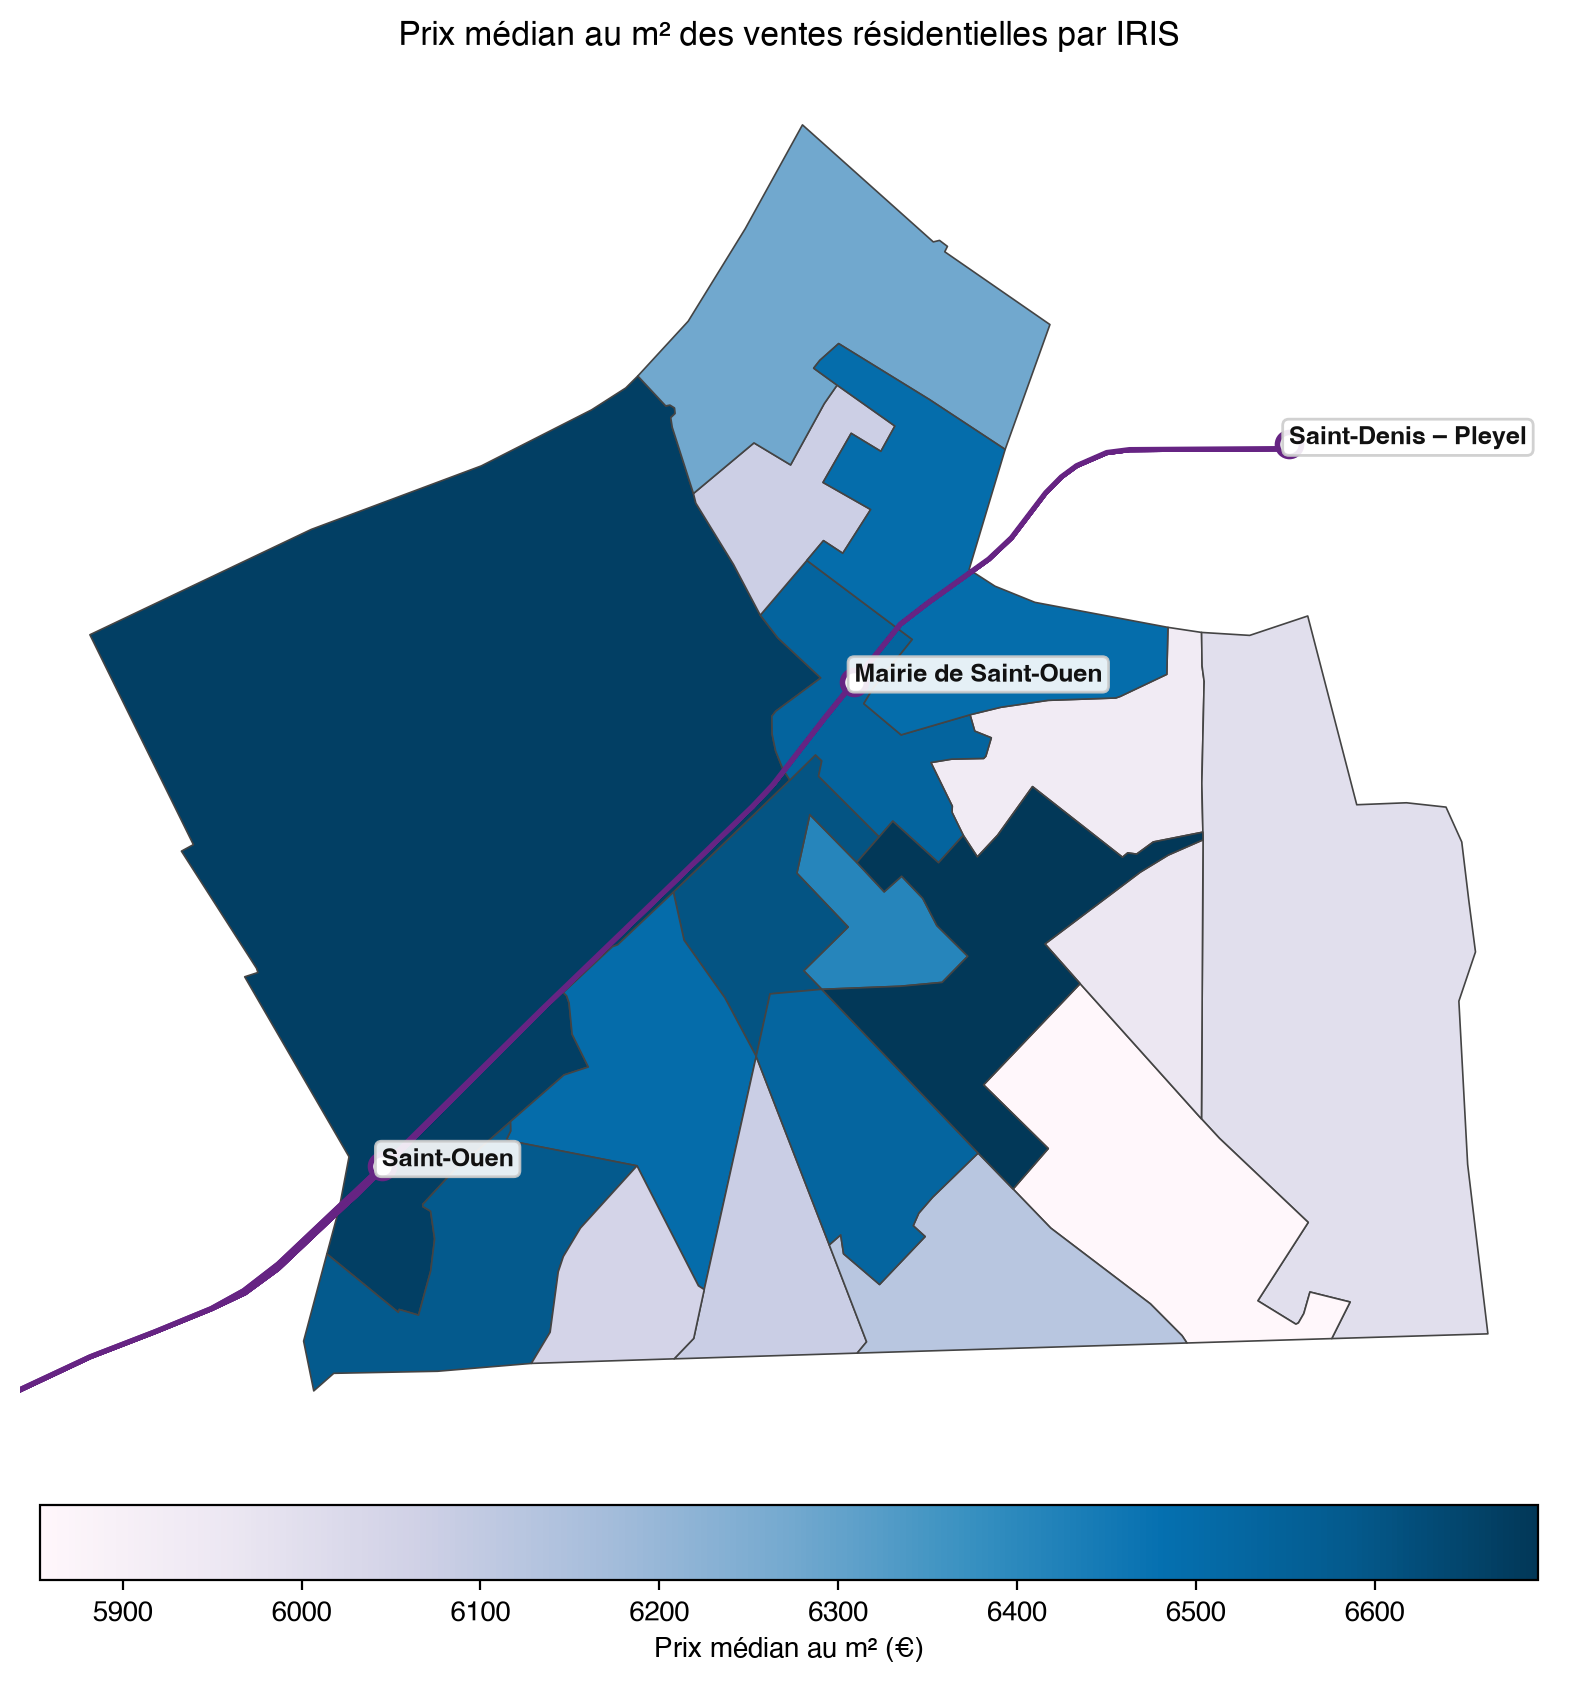

In [28]:
fig, ax = plt.subplots(figsize=(11, 9))

zone_etude_dvf.plot(
    column="prix_m2_median",
    cmap="PuBu",
    linewidth=0.6,
    edgecolor="#444444",
    legend=True,
    legend_kwds={
        "label": "Prix médian au m² (€)",
        "orientation": "horizontal",
        "shrink": 0.7,
        "pad": 0.03,
    },
    missing_kwds={"color": "#e0e0e0", "label": "Aucune vente géolocalisée"},
    ax=ax,
)
traces_transport.plot(ax=ax, color="#662483", linewidth=1.5, zorder=3)
stations_proches.plot(
    ax=ax,
    color="white",
    edgecolor="#662483",
    linewidth=2.0,
    markersize=75,
    zorder=4,
)
etiqueter_stations(ax, stations_proches, fontsize=9)
cadrer_carte(ax, zone_etude)
ax.set_title("Prix médian au m² des ventes résidentielles par IRIS")
plt.tight_layout()
plt.show()


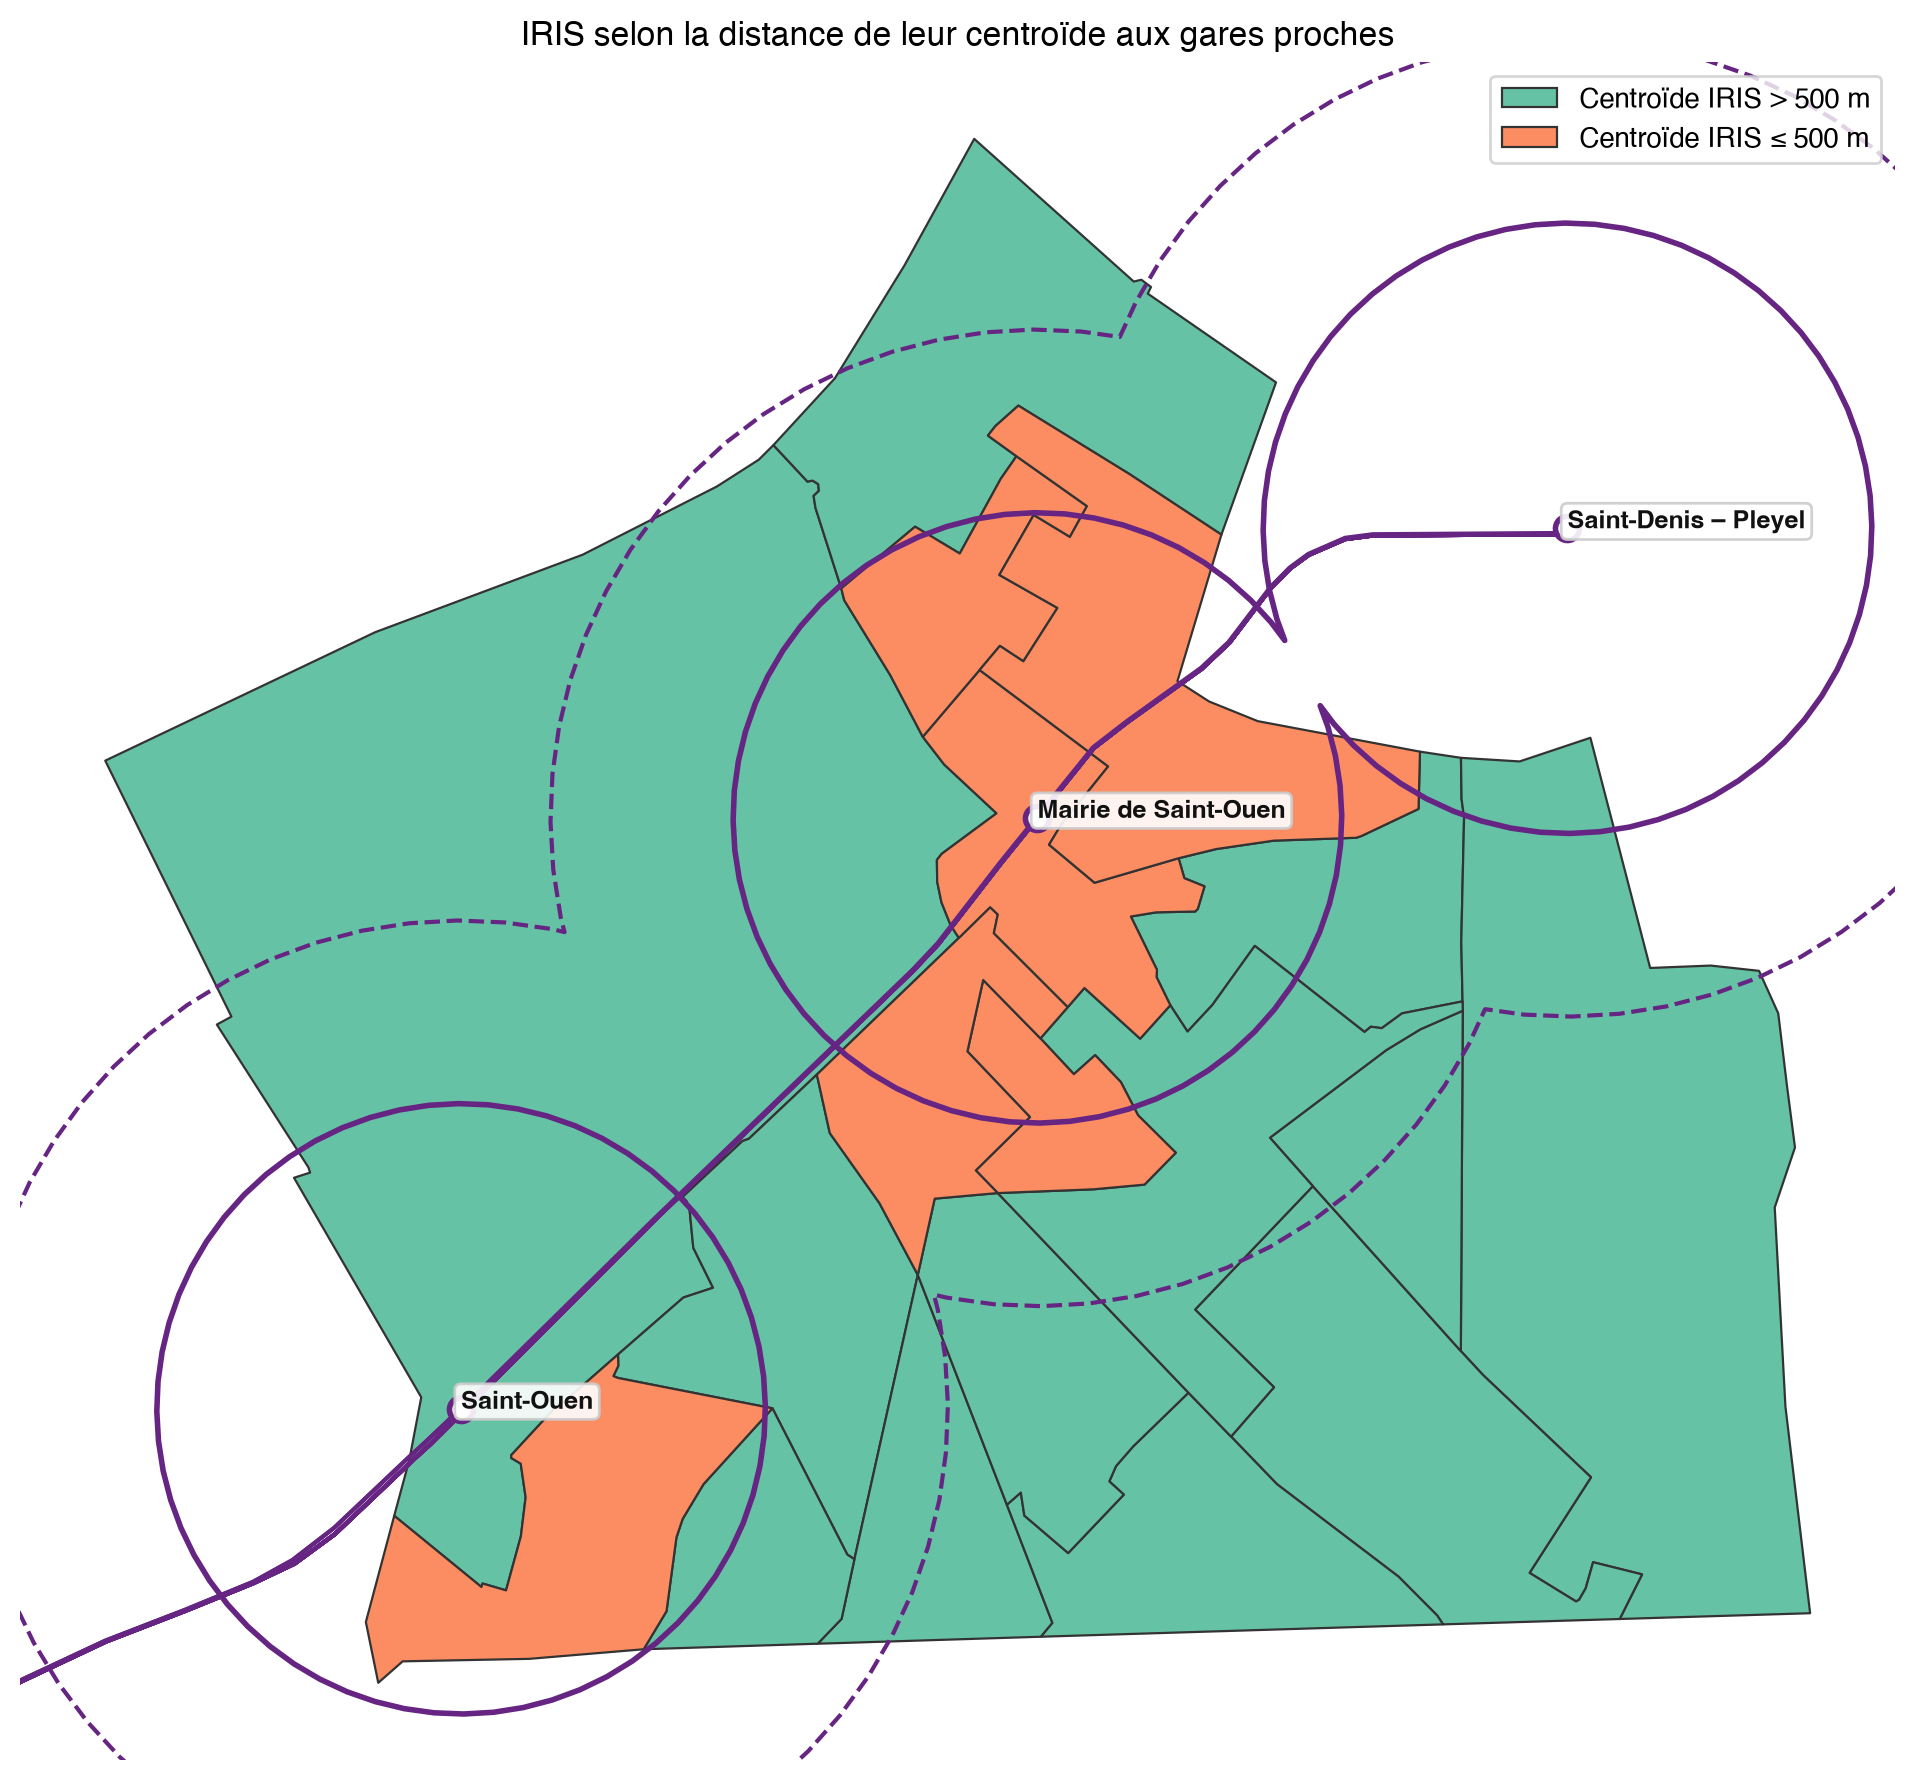

In [29]:
DISTANCE_SEUIL_M = 500
zone_etude_analysis, gdf_buf_500, gdf_buf_800 = calculer_zones_tampons(
    zone_etude,
    stations_proches,
    dist_traitee=DISTANCE_SEUIL_M,
    dist_etendue=800,
)

noms_groupes = {
    f"Zone Traitée (< {DISTANCE_SEUIL_M}m)": f"Centroïde IRIS ≤ {DISTANCE_SEUIL_M} m",
    f"Zone Contrôle (≥ {DISTANCE_SEUIL_M}m)": f"Centroïde IRIS > {DISTANCE_SEUIL_M} m",
}
zone_etude_analysis["groupe"] = zone_etude_analysis["groupe"].replace(noms_groupes)

fig, ax = plt.subplots(figsize=(11, 9))
zone_etude_analysis.plot(
    column="groupe",
    categorical=True,
    cmap="Set2",
    linewidth=0.8,
    edgecolor="#333333",
    legend=True,
    ax=ax,
    zorder=1,
)
gdf_buf_800.plot(
    ax=ax,
    facecolor="none",
    edgecolor="#662483",
    linestyle="--",
    linewidth=1.5,
    zorder=2,
)
gdf_buf_500.plot(
    ax=ax,
    facecolor="none",
    edgecolor="#662483",
    linewidth=2.0,
    zorder=3,
)
traces_transport.plot(ax=ax, color="#662483", linewidth=1.5, zorder=4)
stations_proches.plot(
    ax=ax,
    color="white",
    edgecolor="#662483",
    linewidth=2.0,
    markersize=75,
    zorder=5,
)
etiqueter_stations(ax, stations_proches, fontsize=9)
cadrer_carte(ax, zone_etude_analysis)
ax.set_title("IRIS selon la distance de leur centroïde aux gares proches")
plt.tight_layout()
plt.show()


In [30]:
def analyser_evolution_prix_par_distance(df_ventes, iris_classes):
    """Calcule médianes et effectifs annuels par groupe de distance."""
    ventes_avec_iris = rattacher_ventes_aux_iris(df_ventes, iris_classes)
    groupes_iris = iris_classes[[COL_IRIS, "groupe", "dist_station_m"]].copy()
    df_analyse = ventes_avec_iris.merge(
        groupes_iris,
        on=COL_IRIS,
        how="inner",
        validate="many_to_one",
    )
    table_prix = df_analyse.groupby(["annee", "groupe"])["prix_m2"].median().unstack()
    table_effectifs = df_analyse.groupby(["annee", "groupe"])["prix_m2"].count().unstack()
    return df_analyse, table_prix, table_effectifs


df_analyse, table_prix, table_effectifs = analyser_evolution_prix_par_distance(
    df_logements,
    zone_etude_analysis,
)
print("Prix médian au m² (€) par année et groupe de distance")
print(table_prix.round(0))
print("\nNombre de ventes géolocalisées par année et groupe")
print(table_effectifs)


Prix médian au m² (€) par année et groupe de distance
groupe  Centroïde IRIS > 500 m  Centroïde IRIS ≤ 500 m
annee                                                 
2018                    5292.0                  5366.0
2019                    5866.0                  6066.0
2020                    6314.0                  6386.0
2021                    6773.0                  6965.0
2022                    6970.0                  7019.0
2023                    6970.0                  7019.0
2024                    6360.0                  6385.0
2025                    6466.0                  6451.0

Nombre de ventes géolocalisées par année et groupe
groupe  Centroïde IRIS > 500 m  Centroïde IRIS ≤ 500 m
annee                                                 
2018                       603                     147
2019                       658                     199
2020                       672                     162
2021                       799                     170
2022          

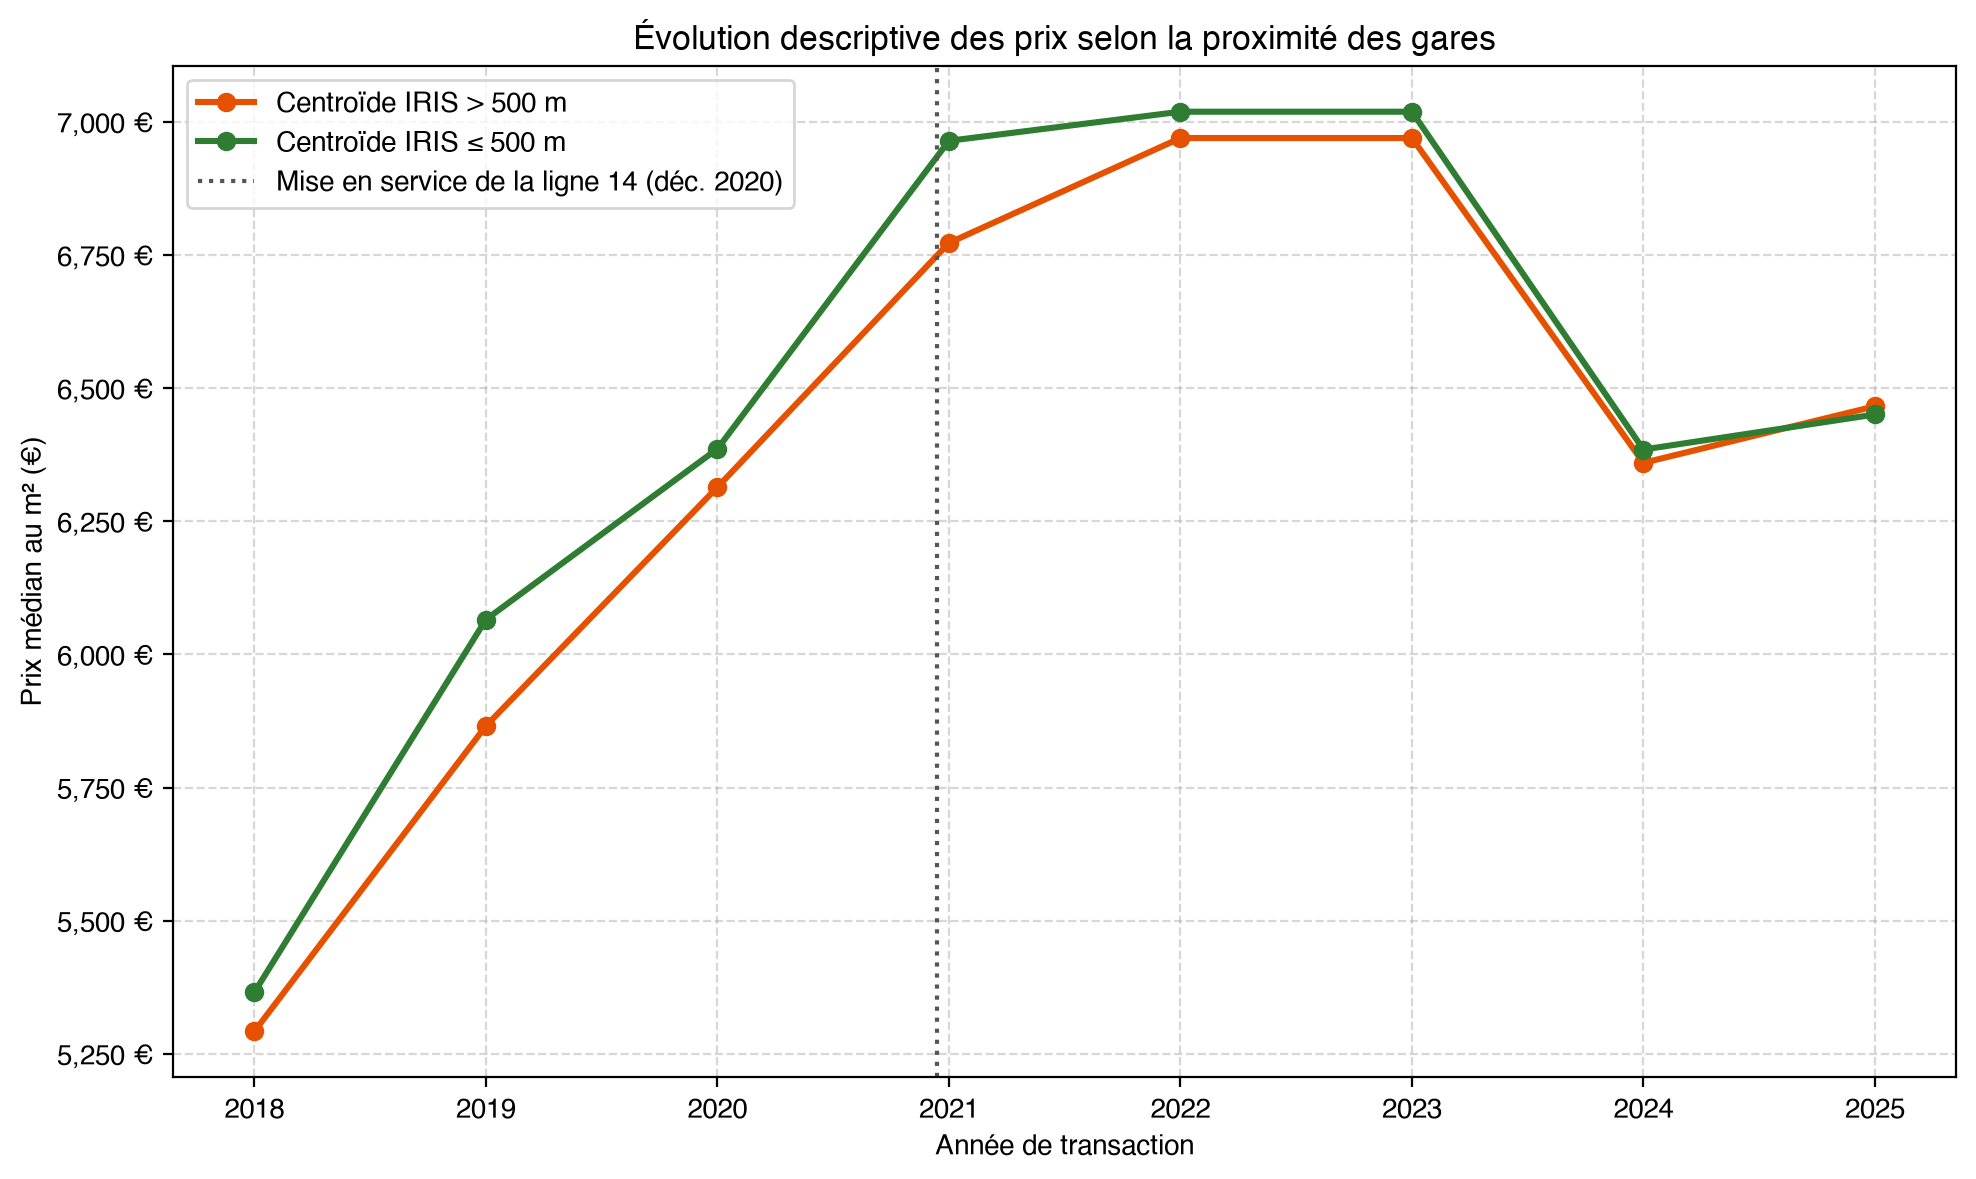

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
couleurs = ["#e65100", "#2e7d32"]

for couleur, groupe in zip(couleurs, table_prix.columns):
    ax.plot(
        table_prix.index,
        table_prix[groupe],
        marker="o",
        linewidth=2.2,
        color=couleur,
        label=groupe,
    )

ax.axvline(
    x=2020.95,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label="Mise en service de la ligne 14 (déc. 2020)",
)
ax.set_title("Évolution descriptive des prix selon la proximité des gares")
ax.set_xlabel("Année de transaction")
ax.set_ylabel("Prix médian au m² (€)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f} €"))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()
